# Distributed BAX Emittance Optimization — A Physics and Software Tutorial

This notebook demonstrates a **local client computer** running a simulated beam-size evaluator and a **remote back-end computer** running the BAX candidate generator through `CloudpickleHTTPGenerator`. It explains the beam physics, the software roles, and the purpose of each code cell.

**Validated example:** the original experiment completed 24 executable code cells successfully. This tutorial edition retains the scientific workflow but has its saved outputs cleared; run it against a compatible back-end to validate your own setup.


## Prerequisites

Before running this experiment, prepare two Python environments:

**Local client computer**

- Install the scientific packages required by this notebook, including Xopt, `bax_algorithms`, PyTorch, and the beam simulation/evaluation dependencies.
- Use an Xopt development version that provides `CloudpickleHTTPGenerator`.
- Run JupyterLab here. The beam simulation and evaluator execute locally.

**Remote back-end computer**

- Start an Xopt HTTPGenerator-compatible service, reachable from the client.
- Install compatible Xopt, `bax_algorithms`, PyTorch, BoTorch, and GPyTorch packages.
- JupyterLab is not required on the back-end.
- Configure `XOPT_REMOTE_URL` on the client to point to this service.

**Important:** The `CloudpickleHTTPGenerator` functionality used here is part of the Xopt HTTPGenerator development work. Until that functionality is merged and released, use a compatible Xopt development branch on both computers.

**Python compatibility:** Prefer matching Python minor versions and compatible Xopt/BAX/scientific dependency versions on both computers. Cloudpickle transports configured Python objects, not an entire Python environment.

**Validation:** This example was successfully exercised with 24 executable cells before the tutorial annotations were added. The current tutorial contains 25 code cells and should be executed again after changes.


## How to read this notebook

Work through the cells from top to bottom. Each code cell has a short explanation immediately before it. The local client needs the notebook, Xopt, beam simulation, and scientific packages used to construct the generator. The remote back-end needs the HTTP service and compatible BAX/scientific dependencies. The remote container does **not** need JupyterLab or the local BeamSim evaluator.


## 1. Connect to the remote back-end computer

The Xopt generator runs on a remote backend; the evaluator runs in this notebook. Establish an SSH tunnel before starting the experiment.

By default, the client connects to `http://127.0.0.1:18002`. Override this with `XOPT_REMOTE_URL` when needed.

The backend requires bearer-token authentication. The token is read from `~/.config/xopt/fedora-http-token` by default; set `XOPT_TOKEN_FILE` to select another credential file. Never commit tokens to Git.


In [ ]:
import os
from pathlib import Path

# Local SSH tunnel to the remote Xopt backend.
REMOTE_XOPT_URL = os.environ.get(
    "XOPT_REMOTE_URL", "http://127.0.0.1:18002"
).rstrip("/")

# Credentials stay outside the notebook and Git repository.
token_path = Path(
    os.environ.get(
        "XOPT_TOKEN_FILE",
        str(Path.home() / ".config/xopt/fedora-http-token"),
    )
).expanduser()

if not token_path.is_file():
    raise FileNotFoundError(
        f"Missing Xopt authentication token file: {token_path}"
    )

REMOTE_XOPT_TOKEN = token_path.read_text().strip()

if not REMOTE_XOPT_TOKEN:
    raise RuntimeError("Xopt authentication token is empty")

print(f"Effective Xopt backend URL: {REMOTE_XOPT_URL}")
print("Authentication token loaded: True (value hidden)")


## 2. Import the software tools

- **Xopt** coordinates the optimization loop.
- **VOCS** describes what the optimizer can change and measure.
- **BaxGenerator** builds a probabilistic model and proposes informative measurements.
- **Evaluator** calls the beam-size measurement function on the local client.
- **PyTorch, NumPy, Matplotlib** provide numerical arrays, models, and plots.

The imports do **not** move the evaluator to the back-end. They make the necessary Python definitions available locally so we can construct the generator that will be serialized.

In [2]:
# Ignore all warnings
import warnings

import matplotlib.pyplot as plt

import torch

from xopt import Xopt
from xopt.vocs import VOCS
from xopt.generators.bayesian.bax_generator import BaxGenerator

from xopt.evaluator import Evaluator

import time
import numpy as np
import random

warnings.filterwarnings("ignore")

/home/ernesto/controls/package/anaconda3/envs/xopt-http-dev/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


### Why use double-precision tensors?

Accelerator calculations and Gaussian-process models can be sensitive to numerical precision. This cell selects 64-bit floating-point tensors as the default for the existing example. It does **not** turn on GPU acceleration.

In [3]:
torch.set_default_tensor_type("torch.DoubleTensor")

# Notebook settings

## 3. Choose experiment settings

**Physics:** We use two input variables. One represents a tuning direction; the other (`meas_dim = 1`) is the quadrupole-scan coordinate. A quadrupole focuses the electron beam differently in the horizontal and vertical planes. Measuring beam size at several quadrupole settings helps infer emittance, a measure of the beam's spread in position and angle.

**Optimization:** We start with `n_obs_init = 10` random measurements, then request `n_iter = 10` additional steps. `n_samples` controls the number of BAX posterior samples. Fixed random seeds help reproduce the example, although distributed execution and numerical libraries can still introduce variation. `use_bmag=False` means the example's emittance objective is not multiplied by the optional mismatch factor.

In [4]:
ndim = 2  # number of input dimensions
noise = False  # whether to add noise to the ground-truth beam size function outputs
thin_lens = False
use_bmag = False
meas_dim = 1  # input dimension for measurement parameter
n_obs_init = 10  # number of random initial observations for GP model
n_samples = 3  # number of posterior samples for BAX
n_iter = 10  # number of optimization steps for Xopt to take (after acquiring random initial data)
rand_seed = 3

# random seeds for reproducibility
torch.manual_seed(rand_seed)
np.random.seed(rand_seed)  # only affects initial random observations through Xopt
random.seed(rand_seed)

# Build test function from single-quadrupole optical beam size model 
Here we define a simple ground-truth beam size function for our optimization problem, where we attempt to find the location in tuning parameter space with minimal emittance. Note that the function "test_func" used to evaluate the ground-truth beam size function takes a dictionary as input and returns a dictionary as the output.

## 4. Load the beamline model (local client)

**Physics:** The beamline configuration provides the quadrupole length (`q_len`), beam energy, and transport matrices (`rmat_x`, `rmat_y`). Transport matrices describe how beam position and angle evolve through the beamline.

**Software:** `BeamSim` and the configuration files stay on the **local client computer**. The remote back-end does not need this simulator to propose candidate settings.

In [5]:
from pyemittance.load_json_configs import load_configs
from pyemittance.simulation import BeamSim

CONFIG = load_configs("LCLS2_OTR0H04")
CONFIG["beamline_info"]

q_len = CONFIG["beamline_info"]["Lquad"]
energy = CONFIG["beamline_info"]["energy"]
rmat_x = torch.tensor(CONFIG["beamline_info"]["rMatx"]).reshape(2, 2)
rmat_y = torch.tensor(CONFIG["beamline_info"]["rMaty"]).reshape(2, 2)
print(rmat_x)
print(rmat_y)

tensor([[1.0000, 2.2000],
        [0.0000, 1.0000]])
tensor([[1.0000, 2.2000],
        [0.0000, 1.0000]])


### Build a simulated electron beam and its measurement function

`BUNCH_PARAMS0` sets the simulated beam charge, horizontal and vertical normalized emittances, Twiss parameters, energy, and particle species. The Twiss parameters describe the beam's phase-space shape.

`measure_beamsize(input_dict)` is our **local evaluator**: it accepts a dictionary of settings, asks `BeamSim` for horizontal and vertical beam sizes, applies the example's detuning/scaling model, and returns `xrms_sq` and `yrms_sq`. These are **squared beam-size observables**, not emittance itself. The `+ 50` terms are part of the example's synthetic measurement model; they are not measurements from real hardware.

The optimizer learns from these returned values. It does not remotely execute `BeamSim`.

In [6]:
BUNCH_PARAMS0 = {
    "total_charge": 50e-12,
    "norm_emit_x": 1e-6,
    "norm_emit_y": 2e-6,
    "beta_x": 10,
    "alpha_x": -1,
    "beta_y": 11,
    "alpha_y": -2,
    "energy": 80e6,
    "species": "electron",
}
sim = BeamSim(bunch_params=BUNCH_PARAMS0, beamline_info=CONFIG["beamline_info"])


# define variables functions
var_names = ["x" + str(i) for i in range(ndim)]
meas_param = var_names[meas_dim]


def measure_beamsize(input_dict):
    scale = 1.0e4
    x_tuning = torch.tensor([])
    for key in input_dict.keys():
        if key != str(meas_param):
            x_tuning = torch.cat((x_tuning, torch.tensor([input_dict[key]])))
    rms_beamsizes0 = np.array(sim.beam_size_meas(input_dict[meas_param]))
    detuning_scale = 1.0 + 1 * x_tuning.abs().sum().cpu()
    xrms, yrms = detuning_scale * rms_beamsizes0
    return {
        "xrms_sq": (float(xrms) * scale) ** 2.0 + 50,
        "yrms_sq": (float(yrms) * scale) ** 2.0 + 50,
    }  # mean-square beam sizes in mm squared

# Construct vocs

## 5. Define VOCS: the optimization contract

**VOCS** means **Variables, Objectives, Constraints, and Constants**. Here we specify the two adjustable variables and their allowed ranges, plus two observables: `xrms_sq` and `yrms_sq`. There is no direct scalar objective declared in this VOCS; the BAX algorithm uses the observables to reason about emittance.

The scan variable gets a wider range because we need measurements on both sides of the quadrupole-scan minimum. Printing the bounds is a useful sanity check before running an optimizer.

In [7]:
variables = {var_name: [-1, 0.5] for var_name in var_names}
variables[meas_param] = [
    -5,
    5,
]  # overwrite bounds for measurement parameter to capture minimum of single-quadrupole optical model

# construct vocs
vocs = VOCS(
    variables=variables,
    observables=["xrms_sq", "yrms_sq"],
)

print("variable_names =", vocs.variable_names)
print("meas_param =", "'" + meas_param + "'")
print("domain =\n", vocs.bounds)

variable_names = ['x0', 'x1']
meas_param = 'x1'
domain =
 [[-1.0, 0.5], [-5.0, 5.0]]


## 6. Define the reference emittance calculation

**Physics:** A quadrupole scan changes focusing. By evaluating beam sizes at several quadrupole strengths, `compute_emit_bmag_quad_scan` reconstructs emittance-related quantities. This helper evaluates the simulated *ground truth* for comparison with the learned model. It is **not** the function Xopt directly minimizes at every step.

**Software:** `lcls_tools` is needed here on the local client for this reference calculation. This cell loops over scan settings and computes a combined horizontal/vertical emittance metric. The optional `use_bmag` switch can include the mismatch factor.

In [8]:
from lcls_tools.common.measurements.emittance_measurement import (
    compute_emit_bmag_quad_scan,
)
from lcls_tools.common.data.model_general_calcs import bdes_to_kmod


def eval_true_emittance(x, use_bmag=False):
    emits = []
    bmags = []
    q = torch.linspace(-3, 3, 11)
    k = bdes_to_kmod(energy, q_len, q)
    k = torch.stack((k, -k))
    rmat = torch.stack((rmat_x, rmat_y))
    twiss0_x = torch.tensor([10, -1])
    twiss0_y = torch.tensor([11, -2])
    twiss0 = torch.cat((twiss0_x.reshape(1, 2), twiss0_y.reshape(1, 2)))
    for setting in x:
        bssx = []
        bssy = []
        input_dict = {
            name: float(setting[i]) for i, name in enumerate(vocs.variable_names)
        }
        for v in q.numpy():
            input_dict[meas_param] = v
            output_dict = measure_beamsize(input_dict)
            bssx += [output_dict["xrms_sq"]]
            bssy += [output_dict["yrms_sq"]]
        bss = torch.tensor([bssx, bssy])

        # compute emittance
        rv = compute_emit_bmag_quad_scan(
            k.numpy(),
            bss.detach().numpy(),
            q_len,
            rmat.numpy(),
            twiss0.numpy(),
            thin_lens=thin_lens,
            maxiter=100,
        )

        emit = torch.from_numpy(rv["emittance"])
        bmag = torch.from_numpy(rv["bmag"])
        emits += [torch.sqrt(emit[0, 0] * emit[1, 0])]
        bmags += [torch.sqrt(bmag[0].min() * bmag[1].min())]
    res = torch.tensor(emits)
    if use_bmag:
        res *= torch.tensor(bmags)
    return res


eval_true_emittance(torch.zeros(1, ndim), use_bmag=use_bmag)

tensor([9.7553])

### Plot the reference curve

This plot sweeps the tuning variable while holding the scan coordinate at its initialized value. It helps us understand where the simulated emittance is small **before** examining the optimizer's predictions. In a real machine, we generally would not know this ground-truth curve in advance.

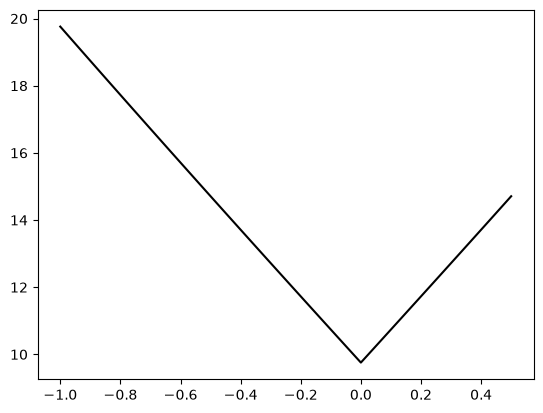

In [9]:
x = torch.zeros(100, ndim)
x[:, 0] = torch.linspace(*vocs.bounds[0], 100)
plt.plot(x[:, 0], eval_true_emittance(x, use_bmag=use_bmag), c="k")

# Prepare generator options.
In this example, we use a specialty covariance module (Matern x Quadratic kernel) for our beam size model.

## 7. Describe how BAX learns from beam-size measurements

**Physics:** Beam size varies smoothly with tuning settings but has a characteristic dependence on quadrupole-scan strength.

**Software:** A **Gaussian process (GP)** is a probabilistic model: it predicts beam size and expresses uncertainty where data are sparse. The custom kernel combines a Matérn term for tuning dimensions with a quadratic polynomial term for the scan dimension. Separate kernels model `xrms_sq` and `yrms_sq`.

This cell configures the model constructor; it does not yet fit a model or communicate with the remote back-end.

In [10]:
from gpytorch.kernels import MaternKernel, PolynomialKernel, ScaleKernel

from xopt.generators.bayesian.models.standard import StandardModelConstructor

# prepare custom covariance module
tuning_dims = list(range(vocs.n_variables))
tuning_dims.remove(meas_dim)
covar_module_x = MaternKernel(
    ard_num_dims=len(tuning_dims), active_dims=tuning_dims, lengthscale_prior=None
) * PolynomialKernel(power=2, active_dims=[meas_dim])

scaled_covar_module_x = ScaleKernel(
    covar_module_x
)  # , outputscale_prior=GammaPrior(2.0, 0.15))
covar_module_y = MaternKernel(
    ard_num_dims=len(tuning_dims), active_dims=tuning_dims, lengthscale_prior=None
) * PolynomialKernel(power=2, active_dims=[meas_dim])
scaled_covar_module_y = ScaleKernel(
    covar_module_y
)  # , outputscale_prior=GammaPrior(2.0, 0.15))

# prepare options for Xopt generator
covar_module_dict = {"xrms_sq": scaled_covar_module_x, "yrms_sq": scaled_covar_module_y}

model_constructor = StandardModelConstructor(
    covar_modules=covar_module_dict, use_low_noise_prior=True
)

### Select an optimizer for candidate search

`LBFGSOptimizer` is used by the Xopt/BAX generator when optimizing its acquisition function—roughly, choosing which new measurement would be most useful. This is different from the physics-side `DifferentialEvolution` optimizer used inside the emittance algorithm.

In [11]:
from xopt.numerical_optimizer import LBFGSOptimizer

numerical_optimizer = LBFGSOptimizer(n_restarts=10, max_time=2)
# numerical_optimizer = GridOptimizer()

# Construct generator, evaluator, Xopt objects

## 8. Construct the BAX algorithm and remote wrapper

**Physics:** `PathwiseMinimizeEmittance` uses modeled horizontal and vertical beam-size scans, beam energy, transport matrices, and Twiss parameters to infer promising emittance-minimizing settings. `DifferentialEvolution` is used within that algorithm.

**Software:** `BaxGenerator` is the scientific generator. `CloudpickleHTTPGenerator` is an Xopt-compatible **proxy**: it serializes the configured generator for execution on the **remote back-end computer**. The local `Evaluator` still calls `measure_beamsize` on the **local client computer**. `Xopt` ties the evaluator and proxy together.

### Why does `vocs` appear three times?

You will see `vocs=vocs` when constructing **(1) `BaxGenerator`, (2) `CloudpickleHTTPGenerator`, and (3) `Xopt`**. They each need the **same optimization contract** for a different role:

- The **BAX generator** needs variable bounds and observable names to model data and propose candidates.
- The **HTTP wrapper** must satisfy the local Xopt generator interface and expose that contract.
- The **Xopt controller** needs the contract to coordinate candidates and evaluation results.

Passing the same local `vocs` variable to three constructors is **not evidence of three network transmissions**. The wrapper may serialize a generator containing VOCS as part of session setup; the exact wire representation and whether objects are deduplicated depend on the implementation. It is safer to say **the definitions must agree**, not that VOCS is sent twice on every iteration.

### Why install BAX on the remote back-end if we use Cloudpickle?

Cloudpickle can serialize a configured Python object, but it does **not** ship a complete Python environment, installed scientific packages, compiled PyTorch libraries, or GPU drivers. The back-end must already have compatible Xopt, `bax_algorithms`, PyTorch, BoTorch, and GPyTorch packages. The local client needs the packages required to **construct** the generator and to run its evaluator/plots. In this example `use_cuda=False`, so remote BAX GPU acceleration is **not** being tested.

In [ ]:
from bax_algorithms.emittance import PathwiseMinimizeEmittance
from bax_algorithms.pathwise.optimize import DifferentialEvolution

# Prepare Algorithm
algo_kwargs = {
    "x_key": "xrms_sq",
    "y_key": "yrms_sq",
    "energy": energy,
    "q_len": q_len,
    "rmat_x": rmat_x,
    "rmat_y": rmat_y,
    "twiss0_x": torch.tensor([10.0, -1.0]),
    "twiss0_y": torch.tensor([11.0, -2.0]),
    "n_samples": n_samples,
    "meas_dim": meas_dim,
    "n_steps_measurement_param": 11,
    "use_bmag": use_bmag,
    "observable_names_ordered": ["xrms_sq", "yrms_sq"],
    "optimizer": DifferentialEvolution(minimize=True, maxiter=10, verbose=True),
    # 'maxiter_fit': 10,
    "crop_scans": False,
}
algo = PathwiseMinimizeEmittance(**algo_kwargs)
# algo = GridMinimizeEmitBmag(**algo_kwargs)
# algo = ScipyMinimizeEmittanceXY(**algo_kwargs)

# construct BAX generator
generator = BaxGenerator(
    vocs=vocs,
    gp_constructor=model_constructor,
    numerical_optimizer=numerical_optimizer,
    algorithm=algo,
    use_cuda=False,
)

generator.gp_constructor.use_low_noise_prior = True
# Wrap the validated BAX generator for remote execution on the remote back-end computer.
from xopt.generators.remote.cloudpickle import CloudpickleHTTPGenerator

remote_generator = CloudpickleHTTPGenerator(
    vocs=vocs,
    generator=generator,
    base_url=REMOTE_XOPT_URL,
    api_key=REMOTE_XOPT_TOKEN,
    timeout=300.0,
    state_timeout=300.0,
)

# construct evaluator
evaluator = Evaluator(function=measure_beamsize)

# construct Xopt optimizer
X = Xopt(evaluator=evaluator, generator=remote_generator, vocs=vocs)

# Optimize

## 9. Collect initial measurements

Before a GP can learn a useful model, it needs data. `X.random_evaluate(n_obs_init)` selects random settings within the VOCS bounds and evaluates the **local** `measure_beamsize` function. These observations become training data for subsequent BAX candidate generation. Random initialization is not the same as the ten adaptive optimization steps below.

In [13]:
# call X.random_evaluate() to generate random initial points and evaluate on test_func
X.random_evaluate(n_obs_init)

,x0,x1,xrms_sq,yrms_sq,xopt_runtime,xopt_error
0,-0.326197,4.701238,128.500827,826.099531,0.004994,False
1,-0.562222,0.431668,62.502374,161.927624,0.000304,False
2,0.063643,-1.491440,96.277857,51.063035,0.000449,False
3,-0.266241,2.215127,54.503387,304.541087,0.000198,False
4,-0.839420,-1.762549,215.441820,52.179909,0.000106,False
5,-0.844440,-0.908628,139.266843,72.189578,0.000133,False
6,0.311622,4.760181,129.512278,823.890367,0.000094,False
7,0.189136,-0.588541,77.744241,67.695749,0.000086,False
8,0.422799,2.407476,58.564205,404.797215,0.000082,False
9,-0.161215,0.848988,52.714173,138.889575,0.000081,False


### Choose a reference point for plots

Visualization helpers often show one or two variables while holding the others at a reference value. This dictionary uses zero for each variable. It is a **plotting reference**, not a newly measured point or a machine command.

In [14]:
reference_point = {var: 0.0 for var in vocs.variable_names}
reference_point

{'x0': 0.0, 'x1': 0.0}

## 10. Build a local *diagnostic* model for visualization

The real BAX candidate generator executes on the remote back-end. Some plotting functions expect direct access to a local `BaxGenerator` and its fitted GP model. To support the plots, we create a **separate diagnostic copy** of the generator on the local client, replace its data with the collected `X.data`, and fit its own model.

**Important:** This diagnostic model is **not the exact remote model instance**. Its plots are a local analysis of the collected observations; they should not be described as reading the remote generator's live internal state.

In [15]:
# HTTP_VISUALIZATION_DIAGNOSTIC_V1
# The HTTP wrapper executes BAX candidate generation on the remote back-end computer.
# Plotting helpers require direct BaxGenerator internals, so we maintain
# an independent diagnostic model on the local client computer, trained on X.data.
# This model is used ONLY for visualization and mean predictions.
import copy

def make_visualization_generator():
    remote = X.generator
    if not hasattr(remote, "generator"):
        raise TypeError("Expected an HTTP generator with a wrapped BaxGenerator")
    if X.data is None or len(X.data) == 0:
        raise RuntimeError("Collect observations before plotting")
    diagnostic = copy.deepcopy(remote.generator)
    # Replace rather than append data to avoid double-counting observations.
    diagnostic.data = X.data.copy(deep=True)
    diagnostic.train_model()
    print(f"Diagnostic model trained locally on the local client computer: {len(diagnostic.data)} observations")
    return diagnostic


### Plot the initial Gaussian-process model

These plots show how the local diagnostic model predicts squared beam size across the two-variable domain and along the scan direction. Look for the shape of the predicted response and uncertainty. `show_acquisition=False` means we are visualizing the model, not the score used to choose the next measurement.

Diagnostic model trained locally on the local client computer: 10 observations
Beginning BAX virtual optimization.
BAX virtual optimization took: 3.3347489833831787 seconds.
Beginning BAX virtual optimization.
BAX virtual optimization took: 2.8769664764404297 seconds.


(<Figure size 600x400 with 2 Axes>,
 array([[<Axes: ylabel='xrms_sq'>],
        [<Axes: xlabel='x1', ylabel='yrms_sq'>]], dtype=object))

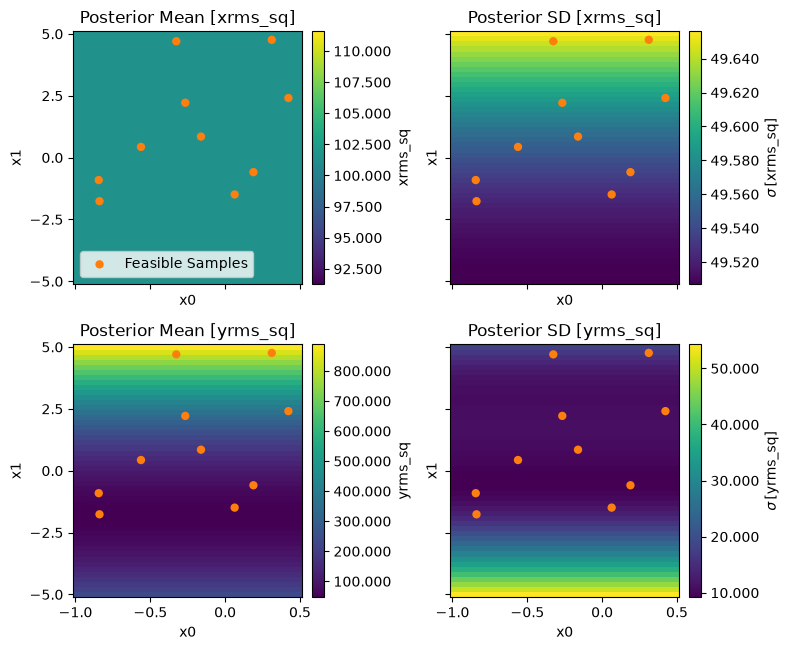

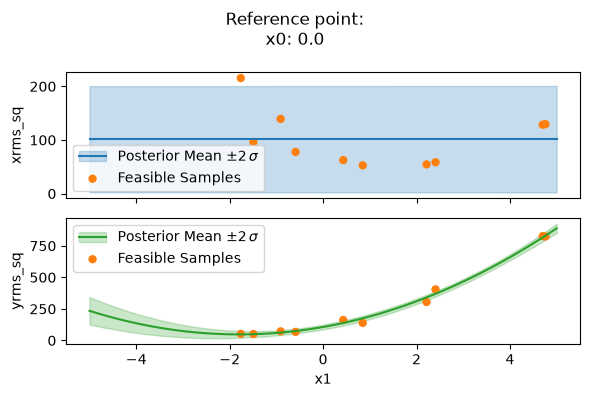

In [16]:
from xopt.generators.bayesian.visualize import visualize_generator_model

viz_generator = make_visualization_generator()
visualize_generator_model(
    viz_generator,
    variable_names=["x0", "x1"],
    reference_point=reference_point,
    show_acquisition=False,
)
visualize_generator_model(
    viz_generator,
    variable_names=["x1"],
    reference_point=reference_point,
    show_acquisition=False,
)

### Plot the BAX virtual-measurement results before adaptive steps

BAX reasons about what an emittance reconstruction would look like under plausible GP predictions. This visualization samples possible virtual measurement outcomes and derived quantities such as emittance and mismatch (`bmag`). The result is a **model-based diagnostic**, not a fresh measurement from the simulator.

4.22464394569397


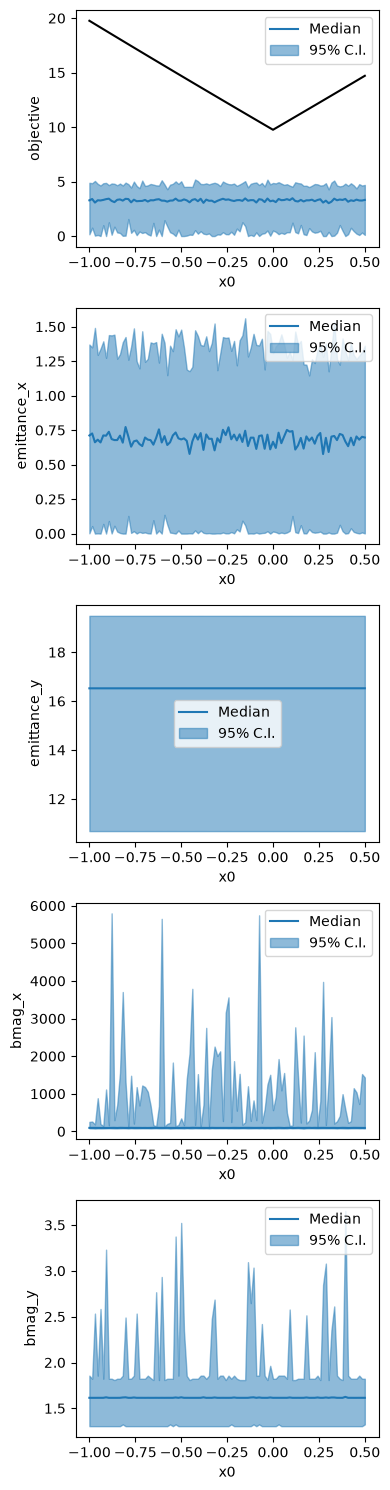

In [17]:
from bax_algorithms.visualize import visualize_virtual_measurement_result

start = time.time()
fig, ax = visualize_virtual_measurement_result(
    viz_generator,
    variable_names=["x0"],
    reference_point=reference_point,
    n_grid=100,
    n_samples=100,
    result_keys=["objective", "emittance_x", "emittance_y", "bmag_x", "bmag_y"],
    # show_samples=True,
)
print(time.time() - start)
x = torch.zeros(100, ndim)
x[:, 0] = torch.linspace(*vocs.bounds[0], 100)
ax[0].plot(x[:, 0], eval_true_emittance(x, use_bmag=use_bmag), c="k")
# plt.ylim(top=0.01)

### Estimate a promising tuning point from the diagnostic model

`get_bax_mean_prediction` applies an optimizer to the locally fitted diagnostic model to estimate a favorable tuning setting. The printed tensor is converted to a dictionary keyed by variable names so it is easier to interpret. This is a **prediction**, not proof of a measured minimum.

In [18]:
from bax_algorithms.utils import get_bax_mean_prediction, tuning_input_tensor_to_dict

mean_optimizer = DifferentialEvolution(
    minimize=True, popsize=100, maxiter=100, verbose=True
)
x_tuning = get_bax_mean_prediction(viz_generator, mean_optimizer)
x_tuning_dict = tuning_input_tensor_to_dict(viz_generator, x_tuning)
print(x_tuning)
print(x_tuning_dict)

Beginning BAX virtual optimization.
BAX virtual optimization took: 0.7929801940917969 seconds.
tensor([[-0.2248]])
{'x0': -0.2248174670059016}


## 11. Run the distributed optimization loop

Each `X.step()` asks the **remote back-end** to generate a candidate and then evaluates that candidate using the **local** beam-size function. The new observation is added to Xopt's data for the next iteration.

The timer measures the **end-to-end step duration**, which can include HTTP communication, remote model work, and local evaluation. It is **not** a pure GPU benchmark. This example runs ten adaptive steps with `use_cuda=False`.

In [19]:
# Full distributed emittance optimization: BAX generation on the remote back-end computer,
# BeamSim evaluation on the local client computer. Retain use_cuda=False for this validation.
remote_step_times = []
for i in range(n_iter):
    start = time.time()
    X.step()
    elapsed = time.time() - start
    remote_step_times.append(elapsed)
    print(f"Remote step {i + 1}/{n_iter}: {elapsed:.2f}s; observations={len(X.data)}")


Remote step 1/10: 11.59s; observations=11
Remote step 2/10: 9.27s; observations=12
Remote step 3/10: 8.81s; observations=13
Remote step 4/10: 8.39s; observations=14
Remote step 5/10: 8.30s; observations=15
Remote step 6/10: 7.21s; observations=16
Remote step 7/10: 8.55s; observations=17
Remote step 8/10: 9.01s; observations=18
Remote step 9/10: 7.47s; observations=19
Remote step 10/10: 8.50s; observations=20


### Check that the full experiment finished

We expect ten initial random observations plus ten adaptive observations. The assertions check the proxy type, configured endpoint, observation count, and any recorded Xopt evaluation errors.

**What this proves:** The notebook's configured distributed workflow completed and produced the expected data. **What it does not prove:** That the back-end used the GPU, that Python/package versions are universally compatible, or that the model found the global physical minimum.

In [20]:
# Verify the completed distributed optimization experiment.
expected = n_obs_init + n_iter
actual = len(X.data)
print("Generator:", type(X.generator).__name__)
print("Endpoint:", X.generator.base_url)
print("Observations:", actual)
print(X.data.tail(3))

assert type(X.generator).__name__ == "CloudpickleHTTPGenerator"
assert X.generator.base_url.rstrip("/") == REMOTE_XOPT_URL.rstrip("/")
assert actual == expected, f"Expected {expected} observations; got {actual}"
if "xopt_error" in X.data.columns:
    assert not X.data["xopt_error"].fillna(False).astype(bool).any(), "Xopt evaluation errors detected"
print(f"Remote emittance full-run verification: PASS ({n_iter} remote steps)")


Generator: CloudpickleHTTPGenerator
Endpoint: http://10.0.0.87:8002
Observations: 20
          x0        x1     xrms_sq    yrms_sq  xopt_runtime  xopt_error
17 -0.232846 -3.889612  260.517111  121.06603      0.001000       False
18  0.011065  3.632217   70.999194  357.80861      0.000825       False
19  0.416780 -3.342381  272.346154  104.04061      0.000876       False
Remote emittance full-run verification: PASS (10 remote steps)


## 12. Refresh the local diagnostic model after optimization

Now that the optimization collected more measurements, fit a **new local diagnostic GP** to the full data set. This lets us compare the model before and after the adaptive measurements. It still does not retrieve the remote generator's internal model state.

In [21]:
start = time.time()
viz_generator = make_visualization_generator()
print(time.time() - start)

Diagnostic model trained locally on the local client computer: 20 observations
0.365100622177124


### Visualize the updated model

These plots use the **local diagnostic model** (`viz_generator`) fitted in the preceding cell. The existing call to `X.generator.train_model()` also requests a model-related operation on the HTTP wrapper; the plotted object remains `viz_generator`, not the remote model. Keeping those two objects conceptually separate avoids misleading readers about where the plotted GP lives.

Beginning BAX virtual optimization.
BAX virtual optimization took: 3.203768730163574 seconds.
Beginning BAX virtual optimization.
BAX virtual optimization took: 2.8925373554229736 seconds.


(<Figure size 600x400 with 2 Axes>,
 array([[<Axes: ylabel='xrms_sq'>],
        [<Axes: xlabel='x1', ylabel='yrms_sq'>]], dtype=object))

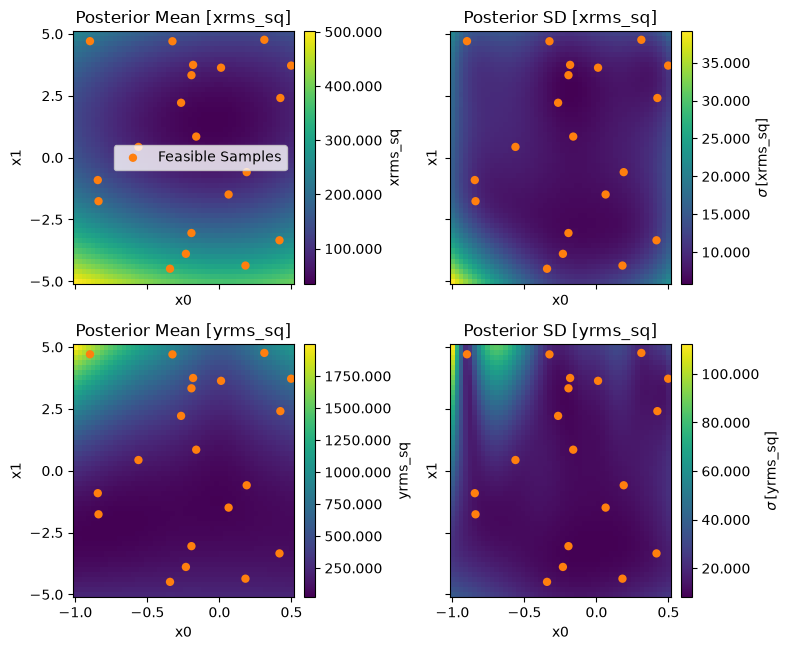

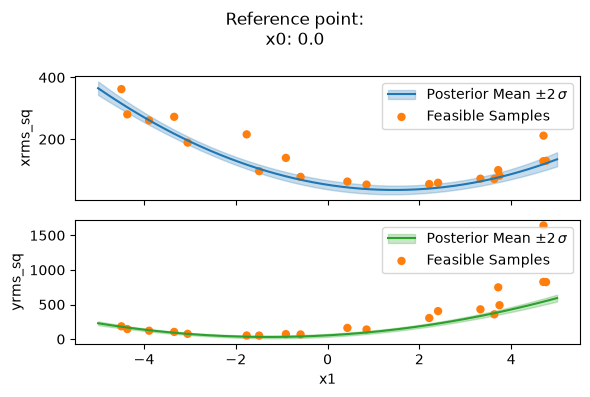

In [22]:
from xopt.generators.bayesian.visualize import visualize_generator_model

X.generator.train_model()
visualize_generator_model(
    viz_generator,
    variable_names=["x0", "x1"],
    reference_point=reference_point,
    show_acquisition=False,
)
visualize_generator_model(
    viz_generator,
    variable_names=["x1"],
    reference_point=reference_point,
    show_acquisition=False,
)

### Inspect updated emittance predictions along one tuning direction

After collecting additional observations, the virtual-measurement plot shows how the diagnostic model now estimates emittance-related quantities along `x0`. Compare this with the earlier plot to see how new data may change the predicted minimum and uncertainty.

3.7629034519195557


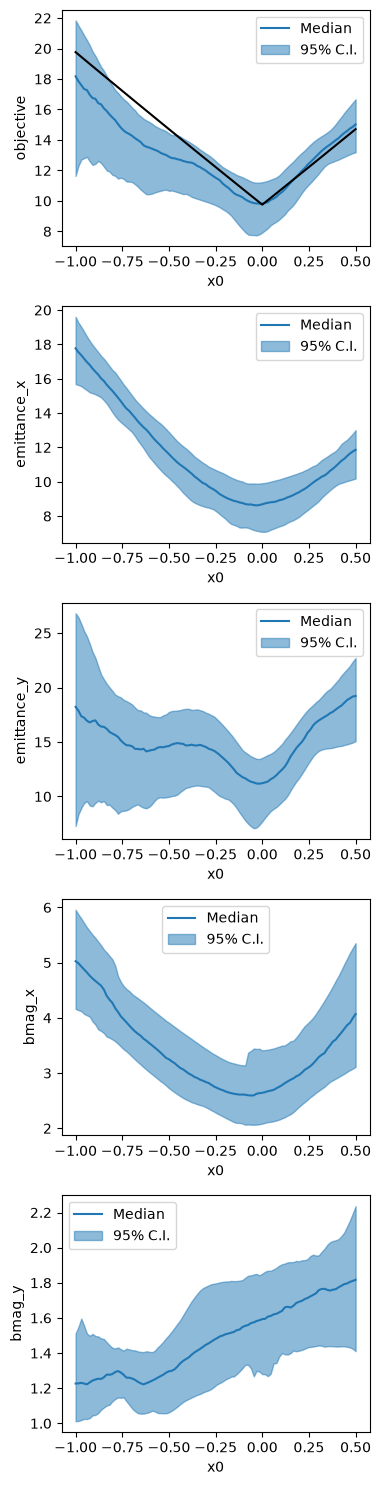

In [23]:
from bax_algorithms.visualize import visualize_virtual_measurement_result

start = time.time()
fig, ax = visualize_virtual_measurement_result(
    viz_generator,
    variable_names=["x0"],
    reference_point=reference_point,
    n_grid=100,
    n_samples=100,
    result_keys=["objective", "emittance_x", "emittance_y", "bmag_x", "bmag_y"],
    # show_samples=True,
)
print(time.time() - start)
x = torch.zeros(100, ndim)
x[:, 0] = torch.linspace(*vocs.bounds[0], 100)
ax[0].plot(x[:, 0], eval_true_emittance(x, use_bmag=use_bmag), c="k")

### Inspect the two-dimensional emittance landscape

This plot explores both `x0` and `x1` in the local diagnostic model. It can help reveal tradeoffs and regions worth investigating. The scan and tuning dimensions have different physical roles, so a two-dimensional plot should not be mistaken for two independent magnet-tuning knobs.

5.209622621536255


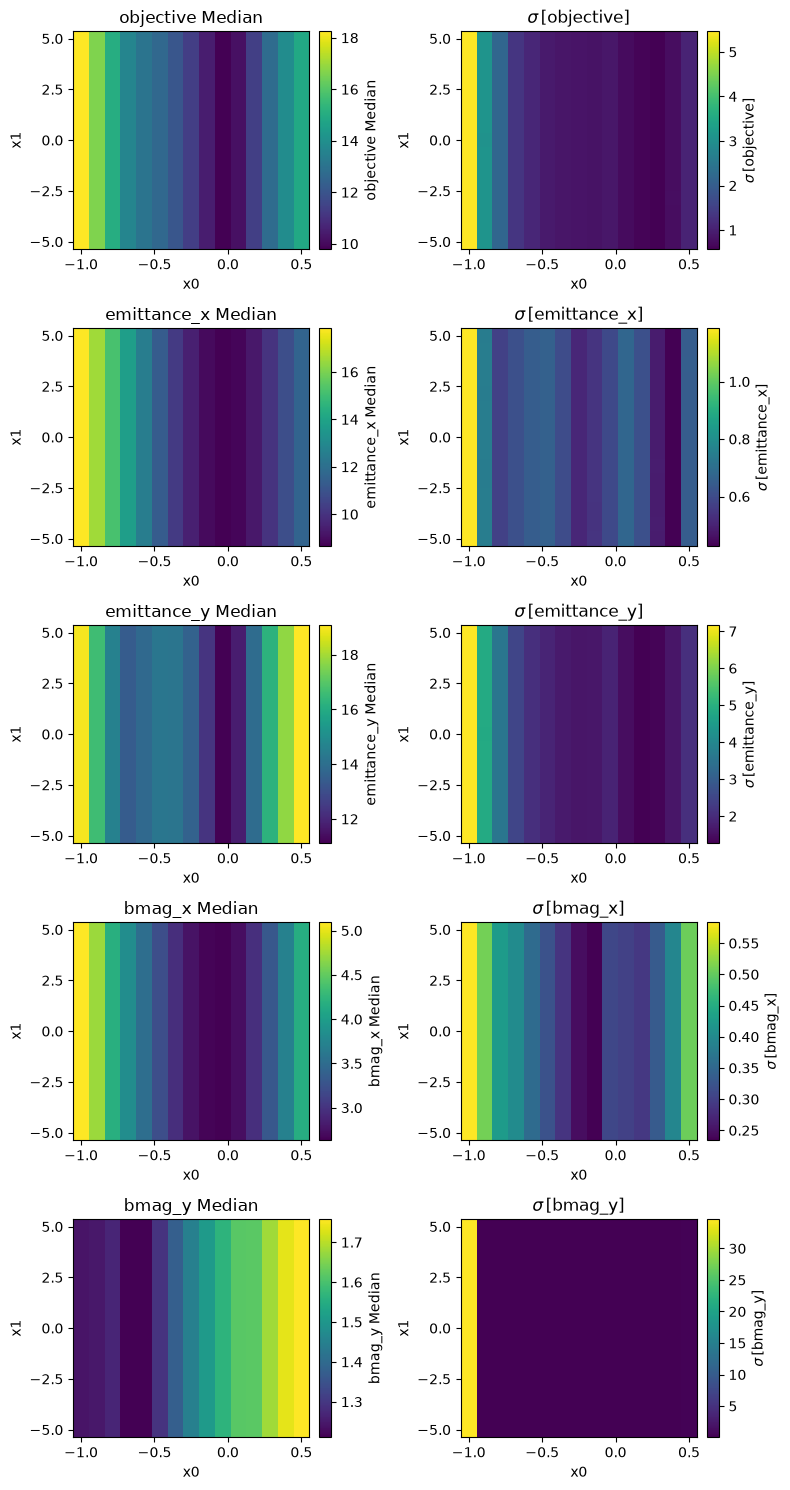

In [24]:
from bax_algorithms.visualize import visualize_virtual_measurement_result

start = time.time()
fig, ax = visualize_virtual_measurement_result(
    viz_generator,
    variable_names=["x0", "x1"],
    reference_point=reference_point,
    n_grid=15,
    n_samples=100,
    result_keys=["objective", "emittance_x", "emittance_y", "bmag_x", "bmag_y"],
    # show_samples=True,
)
print(time.time() - start)

### Report the final predicted tuning setting

We repeat the diagnostic mean-prediction calculation after the adaptive loop. The result is a model-derived suggested setting. A real accelerator workflow would still validate any proposed setting against machine limits, safety checks, and actual measurements.

In [25]:
x_tuning = get_bax_mean_prediction(viz_generator, mean_optimizer)
x_tuning_dict = tuning_input_tensor_to_dict(viz_generator, x_tuning)
print(x_tuning)
print(x_tuning_dict)

Beginning BAX virtual optimization.
BAX virtual optimization took: 2.1488075256347656 seconds.
tensor([[-0.0170]])
{'x0': -0.016961553911267246}
